# L'intégrale triangle scalaire à une boucle — trois voies, contrôles et reconnaissance de constantes

Ce carnet calcule **une** intégrale de Feynman : le *triangle scalaire* à une boucle (propagateurs internes sans masse), en dimension 4 euclidienne. C'est l'une des briques de base des corrections radiatives — et l'un des objets de la famille « 30 intégrales de Feynman » du harnais [BootLoops](https://github.com/BootLoops-ai/bootloops) (MIT), rapportée par Matthew Schwartz dans *Claude-shaped science* (2025). Il est la **veine V3** de la distillation [issue #20428](https://github.com/jsboige/CoursIA/issues/20428), après le carnet de marches ([Marches-01](../../Probas/Applications/Marches/README.md), veine V1).

Fil directeur, en trois gestes — les mêmes protocoles que le carnet V1, appliqués à un objet différent :

1. **Trois voies de calcul** du même objet, chacune vérifiable : paramètres de Feynman (quadrature 2D), substitution homogène (rectangle), intégration analytique d'une variable (quadrature 1D) ;
2. **Des contrôles qui mordent** : micro-contrôle de l'intégrale analytique, contrôle négatif qui *doit* échouer, point aveugle du contrôle identifié ;
3. **Une reconnaissance de constantes** à anneau **déclaré avant la recherche** (protocole *constant-recognition*) : sur la famille isocèle, la forme fermée est identifiée puis certifiée à ~38 chiffres sur six angles — sans jamais inventer de constante.

**Ce que ce carnet n'est pas** : une preuve. La certification est **numérique haute précision**, croisée sur des routes indépendantes — le §7 dit exactement ce que cela prouve, et ce que cela ne prouve pas.

**Prérequis** : `mpmath`, `numpy`, `matplotlib`. Aucun bagage en théorie quantique des champs n'est requis : la dérivation de la représentation intégrale est faite au §1.

## 1. Le cadre : définir l'objet avant de le calculer

Le triangle scalaire à une boucle : trois propagateurs scalaires sans masse, un moment externe par sommet. En dimension $D = 4$ euclidienne, avec des moments externes $p_1, p_2, p_3$ tels que $p_1 + p_2 + p_3 = 0$, l'amplitude s'écrit

$$C_0 \;\equiv\; \int \frac{d^4k}{(2\pi)^4}\;\frac{1}{k^2\,(k+p_1)^2\,(k+p_1+p_2)^2}\,.$$

Les invariants cinématiques sont $\alpha = p_1^2$, $\beta = p_2^2$, $\gamma = p_3^2$ : un seul objet dépend de trois nombres — c'est ce qui rend le carnet borné.

**Paramètres de Feynman.** On part de $\frac{1}{ABC} = 2\int_{\text{simplexe}} \frac{dx_2\,dx_3}{(x_1 A + x_2 B + x_3 C)^3}$, avec $x_1 = 1 - x_2 - x_3$, $x_i \geq 0$ :

$$x_1 k^2 + x_2 (k+p_1)^2 + x_3 (k+p_1+p_2)^2 = k^2 + 2k\cdot\big(x_2 p_1 + x_3 (p_1{+}p_2)\big) + x_2\alpha + x_3\gamma\,.$$

En posant $b = x_2 p_1 + x_3 (p_1{+}p_2)$ et en translatant $k \to k - b$, le dénominateur devient $k^2 + \Delta$ avec — en utilisant $p_1\cdot(p_1{+}p_2) = (\alpha+\gamma-\beta)/2$ et $x_1 + x_2 + x_3 = 1$ :

$$\boxed{\;\Delta \;=\; \alpha\, x_1 x_2 \;+\; \gamma\, x_1 x_3 \;+\; \beta\, x_2 x_3\;}$$

**Intégration sur la boucle.** En $D = 4$ : $\int \frac{d^4k}{(2\pi)^4} \frac{1}{(k^2+\Delta)^3} = \frac{1}{(4\pi)^2}\,\frac{\Gamma(1)}{\Gamma(3)}\,\Delta^{-1} = \frac{1}{32\pi^2\,\Delta}$, d'où, en combinant avec le facteur $2! = 2$ :

$$C_0 \;=\; \frac{J}{16\pi^2}\,,\qquad J(\alpha,\beta,\gamma) \;=\; \iint_{\text{simplexe}} \frac{dx_2\,dx_3}{\Delta}\,.$$

Tout le carnet porte sur $J$ ; le facteur $16\pi^2$ est une simple conversion.

**Une convention, un choix.** Le même objet s'écrit aussi avec la base de propagateurs $\{k,\; k+p_1,\; k+p_2\}$, qui fait apparaître $\delta = |p_1 - p_2|^2 = 2(\alpha+\beta)-\gamma$ à la place de $\gamma$ : c'est le *même* objet, à relabelage des moments près. On garde le $\Delta$ canonique ci-dessus.

**Réalisabilité euclidienne.** Un triplet $(\alpha,\beta,\gamma)$ est réalisable si et seulement si $\big|\sqrt{\alpha}-\sqrt{\beta}\big| \leq \sqrt{\gamma} \leq \sqrt{\alpha}+\sqrt{\beta}$ — l'inégalité triangulaire des racines (l'exercice 1 la démontre par Cauchy–Schwarz à partir de $p_3 = -(p_1+p_2)$). Le carnet reste sur ce domaine.

In [1]:
# Socle : mpmath (precision arbitraire), numpy/matplotlib (figure du §1).
import time
import mpmath
import numpy as np
import matplotlib.pyplot as plt
from mpmath import mp, mpf, quad, sqrt, log, pi, sin, cos, clsin, clcos, nstr

mp.dps = 30  # precision de travail par defaut (portee a 40 au §6)

def triangle_reel(alpha, beta, gamma):
    """Realisabilite euclidienne : inegalite triangulaire des racines carrees."""
    ra, rb, rg = sqrt(mpf(alpha)), sqrt(mpf(beta)), sqrt(mpf(gamma))
    return abs(ra - rb) <= rg <= ra + rb

print("mpmath", mpmath.__version__, "| precision de travail : mp.dps =", mp.dps)

mpmath 1.3.0 | precision de travail : mp.dps = 30


In [2]:
# Les quatre cinematiques du carnet (+ controle de realisabilite).
CINEMATIQUES = [(1, 1, 3), (1, 1, 2), (1, 2, mpf('2.5')), (1, 1, mpf('3.9'))]

print("Les quatre cinematiques :")
for (a, b, g) in CINEMATIQUES:
    ra, rb, rg = sqrt(mpf(a)), sqrt(mpf(b)), sqrt(mpf(g))
    print(f"  (alpha, beta, gamma) = ({a}, {b}, {g})   "
          f"racines ({nstr(ra, 6)}, {nstr(rb, 6)}, {nstr(rg, 6)})   "
          f"reel : {'oui' if triangle_reel(a, b, g) else 'NON'}")

Les quatre cinematiques :
  (alpha, beta, gamma) = (1, 1, 3)   racines (1.0, 1.0, 1.73205)   reel : oui
  (alpha, beta, gamma) = (1, 1, 2)   racines (1.0, 1.0, 1.41421)   reel : oui
  (alpha, beta, gamma) = (1, 2, 2.5)   racines (1.0, 1.41421, 1.58114)   reel : oui
  (alpha, beta, gamma) = (1, 1, 3.9)   racines (1.0, 1.0, 1.97484)   reel : oui


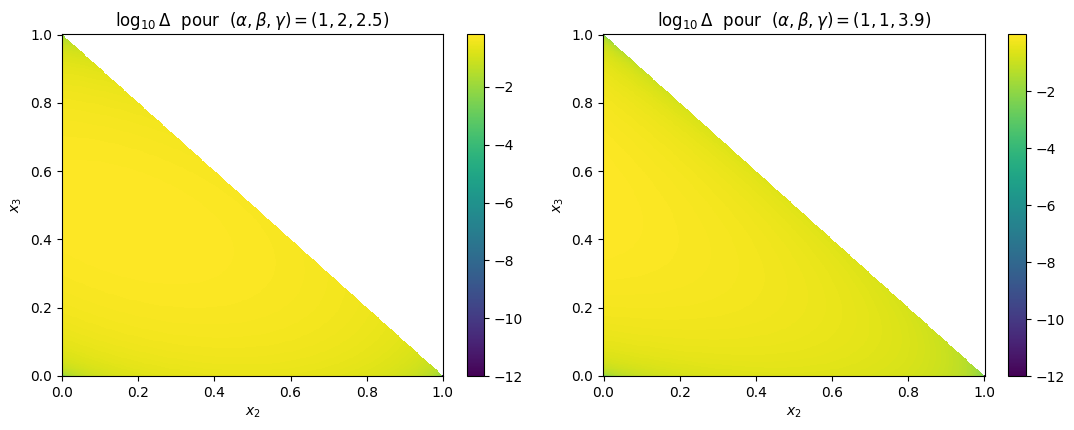

In [3]:
# Figure 1 : ou vit l'integrande ? Delta sur le simplexe (x2, x3), x1 = 1 - x2 - x3.
def delta_simplexe(alpha, beta, gamma, x2, x3):
    x1 = 1.0 - x2 - x3
    return alpha * x1 * x2 + gamma * x1 * x3 + beta * x2 * x3

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (a, b, g) in zip(axes, [(1, 2, 2.5), (1, 1, 3.9)]):
    n = 401
    x2 = np.linspace(0.0, 1.0, n)
    x3 = np.linspace(0.0, 1.0, n)
    X2, X3 = np.meshgrid(x2, x3)
    D = delta_simplexe(float(a), float(b), float(g), X2, X3)
    D = np.ma.masked_where(X2 + X3 > 1.0, D)
    img = ax.pcolormesh(X2, X3, np.log10(np.maximum(D, 1e-12)), shading='auto', cmap='viridis')
    ax.set_title(f"$\\log_{{10}}\\Delta$  pour  $(\\alpha,\\beta,\\gamma)=({a},{b},{g})$")
    ax.set_xlabel("$x_2$")
    ax.set_ylabel("$x_3$")
    fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

**Lecture.** $\Delta$ s'annule sur les trois bords du simplexe ($x_i x_j = 0$) et reste strictement positif à l'intérieur : l'intégrande $1/\Delta$ diverge aux coins mais reste intégrable — la structure typique d'une intégrale de Feynman convergente. Le panneau de droite, $(\alpha,\beta,\gamma) = (1, 1, 3.9)$, est proche de la dégénérescence ($\sqrt{3.9} \approx 1{,}975$, tout près de $\sqrt{\alpha}+\sqrt{\beta} = 2$) : la vallée se resserre et la quadrature devient plus difficile — c'est le **point de stress** du carnet, qui mettra les trois voies à l'épreuve au §5.

## 2. Voie A — quadrature 2D sur le simplexe

La voie la plus directe : intégrer numériquement sur le simplexe, par deux quadratures imbriquées — pour chaque $x_2 \in [0,1]$, l'intégrale intérieure porte sur $x_3 \in [0, 1-x_2]$.

**Piège d'outil attrapé en construisant le carnet.** `mpmath` 1.3.0 ne supporte pas les bornes *callables* dans le `quad` multidimensionnel : la forme « naturelle » `quad(f, [0,1], [0, lambda x2: 1-x2])` **paraît** acceptée et échoue plus tard, à l'intérieur de la somme de quadrature (`TypeError`). La cellule suivante montre le piège attrapé, puis la parade (imbrication manuelle) — même esprit que le piège d'annulation d'exposant du carnet V1 : un instrument se vérifie avant qu'on lui fasse confiance.

In [4]:
# Voie A -- le piege attrape, puis la parade.
try:
    _ = mp.quad(lambda x2, x3: 1.0, [0, 1], [lambda x2: 0, lambda x2: 1 - x2])
    print("mpmath", mpmath.__version__, ": bornes callables acceptees (comportement posterieur a 1.3.0)")
except TypeError as e:
    print("mpmath", mpmath.__version__, ": TypeError attrape ->", str(e)[:90])
    print("  les bornes callables du quad 2D sont consommees en interne ; la forme paraissait")
    print("  valide et echoue dans la somme. Parade : imbriquer un quad dans l'autre.")

def J_A(alpha, beta, gamma):
    """Voie A : 2D imbriquee sur le simplexe (x2, x3)."""
    a, b, g = mpf(alpha), mpf(beta), mpf(gamma)
    def inner(x2):
        def f(x3):
            x1 = 1 - x2 - x3
            return 1 / (a * x1 * x2 + g * x1 * x3 + b * x2 * x3)
        return quad(f, [0, 1 - x2])
    return quad(inner, [0, 1])

t0 = time.time()
JA_demo = J_A(1, 2, mpf('2.5'))
dt = time.time() - t0
print(f"\nJ_A(1, 2, 2.5)  = {nstr(JA_demo, 25)}   [{dt:.1f} s a dps = {mp.dps}]")
print(f"C0^E(1, 2, 2.5) = J/(16 pi^2) = {nstr(JA_demo / (16 * pi**2), 12)}")

mpmath 1.3.0 : TypeError attrape -> cannot create mpf from <function <lambda> at 0x0000022E77790180>
  les bornes callables du quad 2D sont consommees en interne ; la forme paraissait
  valide et echoue dans la somme. Parade : imbriquer un quad dans l'autre.



J_A(1, 2, 2.5)  = 1.3427652838373602509494   [1.8 s a dps = 30]
C0^E(1, 2, 2.5) = J/(16 pi^2) = 0.00850316049452


**Lecture.** La voie A rend $J(1, 2, 2{,}5) \approx 1{,}342765283837360250949$ en quelques secondes : c'est la **référence** du carnet, mais aussi la plus lente — chaque point coûte une quadrature imbriquée. Les voies B et C devront reproduire ces mêmes chiffres, plus vite.

## 3. Voie B — substitution homogène : le simplexe devient un rectangle

On exploite l'homogénéité du simplexe : posons $x_2 = uv$, $x_3 = u(1-v)$ avec $(u,v) \in [0,1]^2$ (jacobien $u$ ; $x_1 = 1-u$ ; la variable $v$ décrit le *rapport* $x_3/x_2$). Alors

$$\Delta = u\,\Big[(1-u)\big(\alpha v + \gamma(1-v)\big) + \beta\, u\, v(1-v)\Big]
\quad\Longrightarrow\quad
J = \iint_{[0,1]^2} \frac{du\,dv}{(1-u)\big(\alpha v + \gamma(1-v)\big) + \beta\,u\,v(1-v)}\,.$$

Deux bénéfices numériques : le domaine devient un **rectangle** — le `quad` 2D intégré de mpmath redevient utilisable, sans bornes callables — et le facteur $(1-u)$ refactorise la singularité du coin $x_1 \to 0$ du côté « $u$ », laissant une intégrande lisse.

In [5]:
def J_B(alpha, beta, gamma):
    """Voie B : 2D rectangulaire en (u, v) -- x2 = u v, x3 = u (1-v)."""
    a, b, g = mpf(alpha), mpf(beta), mpf(gamma)
    def f(u, v):
        return 1 / ((1 - u) * (a * v + g * (1 - v)) + b * u * v * (1 - v))
    return quad(f, [0, 1], [0, 1])

t0 = time.time()
JB_demo = J_B(1, 2, mpf('2.5'))
dt = time.time() - t0
print(f"J_B(1, 2, 2.5) = {nstr(JB_demo, 25)}   [{dt:.1f} s]")
print(f"|J_A - J_B|    = {nstr(abs(JA_demo - JB_demo), 3)}")

J_B(1, 2, 2.5) = 1.3427652838373602509494   [1.0 s]
|J_A - J_B|    = 0.0


**Lecture.** Mêmes chiffres que la voie A, et la quadrature rectangulaire va plus vite. La leçon est générale : **changer de coordonnées avant de régler l'algorithme** — une paramétrisation qui épouse la géométrie de l'intégrale vaut mieux que le réglage fin d'un algorithme sur une paramétrisation mal adaptée.

## 4. Voie C — intégrer une variable à la main : plus qu'une quadrature 1D

Fixons $u$ (cadre de la voie B). L'intégrande en $v$ a une **quadratique** au dénominateur :

$$D(u,v) = C + B v - A v^2,\qquad A = \beta\, u,\quad B = (1-u)(\alpha - \gamma) + \beta\, u,\quad C = \gamma\,(1-u).$$

Comme $D > 0$ sur $[0,1]$, les racines $r_\pm = \frac{B \pm \sqrt{B^2 + 4AC}}{2A}$ encadrent l'intervalle ($r_- < 0 < 1 < r_+$), et une décomposition en éléments simples donne

$$\int_0^1 \frac{dv}{D(u,v)} \;=\; \frac{1}{\sqrt{B^2+4AC}}\left[\,\ln\frac{v - r_-}{r_+ - v}\,\right]_{v=0}^{v=1}\,.$$

Il ne reste qu'**une** quadrature (en $u$) : c'est la voie qui fait travailler le plus d'algèbre et le moins de machine.

In [6]:
def I_v(u, alpha, beta, gamma):
    """Integrale exacte en v de 1/(C + B v - A v^2) sur [0, 1]."""
    a, b, g = mpf(alpha), mpf(beta), mpf(gamma)
    u = mpf(u)
    A = b * u
    B = (1 - u) * (a - g) + b * u
    C = g * (1 - u)
    if A == 0:                       # cas lineaire (beta = 0, ou u = 0)
        return (1 / B) * log((B + C) / C)
    D = B * B + 4 * A * C
    sD = sqrt(D)
    rp = (B + sD) / (2 * A)
    rm = (B - sD) / (2 * A)
    def F(v):
        return log((v - rm) / (rp - v)) / sD
    return F(mpf(1)) - F(mpf(0))

def J_C(alpha, beta, gamma):
    """Voie C : quadrature 1D en u de l'integrale en v exacte."""
    return quad(lambda u: I_v(u, alpha, beta, gamma).real, [0, 1])

t0 = time.time()
JC_demo = J_C(1, 2, mpf('2.5'))
dt = time.time() - t0
print(f"J_C(1, 2, 2.5) = {nstr(JC_demo, 25)}   [{dt:.1f} s]")
print(f"|J_A - J_C|    = {nstr(abs(JA_demo - JC_demo), 3)}")

J_C(1, 2, 2.5) = 1.3427652838373602509494   [0.0 s]
|J_A - J_C|    = 0.0


In [7]:
# Micro-controle : I_v analytique contre une quadrature 1D directe en v (u = 0.37).
u0 = mpf('0.37')
Iv_ana = I_v(u0, 1, 2, mpf('2.5'))
Iv_num = quad(lambda v: 1 / ((1 - u0) * (1 * v + mpf('2.5') * (1 - v)) + 2 * u0 * v * (1 - v)), [0, 1])
print(f"u = 0.37 : I_v analytique = {nstr(Iv_ana, 22)}")
print(f"           I_v numerique  = {nstr(Iv_num, 22)}")
print(f"           |diff|         = {nstr(abs(Iv_ana - Iv_num), 3)}")

u = 0.37 : I_v analytique = 0.8692986025622281534397
           I_v numerique  = 0.8692986025622281534397
           |diff|         = 0.0


**Lecture.** L'accord à la précision de travail valide la formule des racines $r_\pm$ **point par point**, pas seulement en moyenne — c'est ce micro-contrôle qui rend la voie C crédible là où un accord A/B/C global ne suffirait pas (les trois voies partagent la même paramétrisation de Feynman ; cf. §5).

## 5. Table d'accord et contrôles croisés — ce que trois voies prouvent, et ce qu'elles ne prouvent pas

**Independence bookkeeping** (la discipline, pas la formule) : les voies A, B et C ne sont **pas trois dérivations indépendantes** — toutes partent de la même représentation de Feynman. Ce sont trois stratégies de quadrature *et d'algèbre* différentes : leur accord détecte les erreurs de **mise en œuvre** (jacobien faux, racines fausses, bornes fausses), pas une erreur de **paramétrisation** commune. Les contrôles qui portent, eux, sur l'objet et non sur l'implémentation, sont : le micro-contrôle du §4, la reconnaissance de constantes du §6, et — un jour — une preuve analytique.

In [8]:
print("Les trois voies, dps = 30 (les ecarts sont ceux a la precision de travail) :")
print(f"{'cinematique':<26}{'J par la voie A (22 chiffres)':<32}{'|A-B|':<10}{'|A-C|':<10}")
tA = tB = tC = 0.0
for (a, b, g) in CINEMATIQUES:
    t0 = time.time(); JA = J_A(a, b, g); tA += time.time() - t0
    t0 = time.time(); JB = J_B(a, b, g); tB += time.time() - t0
    t0 = time.time(); JC = J_C(a, b, g); tC += time.time() - t0
    print(f"({a}, {b}, {g})".ljust(26) + f"{nstr(JA, 22):<32}{nstr(abs(JA - JB), 2):<10}{nstr(abs(JA - JC), 2):<10}")
print(f"\ntemps cumules sur les 4 points : A {tA:.1f} s | B {tB:.1f} s | C {tC:.1f} s")

Les trois voies, dps = 30 (les ecarts sont ceux a la precision de travail) :
cinematique               J par la voie A (22 chiffres)   |A-B|     |A-C|     


(1, 1, 3)                 1.562604825792972593734         0.0       0.0       


(1, 1, 2)                 1.831931188354438030109         0.0       0.0       


(1, 2, 2.5)               1.342765283837360250949         0.0       0.0       


(1, 1, 3.9)               1.401303197892613264733         0.0       0.0       

temps cumules sur les 4 points : A 6.9 s | B 5.2 s | C 0.1 s


In [9]:
# Le meme J est-il symetrique ? Test de permutation (voie C, dps = 30).
perms = [(1, 2, 3), (2, 1, 3), (1, 3, 2), (3, 2, 1)]
vals = [J_C(*p) for p in perms]
for p, v in zip(perms, vals):
    print(f"  J{p} = {nstr(v, 22)}")
print("max |J - J(1,2,3)| =", nstr(max(abs(v - vals[0]) for v in vals), 3))

  J(1, 2, 3) = 1.254138667411437103276
  J(2, 1, 3) = 1.254138667411437103276
  J(1, 3, 2) = 1.254138667411437103276
  J(3, 2, 1) = 1.254138667411437103276
max |J - J(1,2,3)| = 0.0


**Lecture.** Les quatre permutations de $(\alpha,\beta,\gamma)$ rendent le **même** J à la précision de travail : la symétrie sous permutation des invariants externes est vérifiée — et elle n'était pas une évidence depuis la forme de $\Delta$, qui distingue les trois paires $x_i x_j$. Le point de stress $(1, 1, 3.9)$ passe sans difficulté ; la voie C est la plus rapide des trois.

## 6. La famille isocèle : identification à anneau déclaré

**Protocole *constant-recognition*.** Avant toute recherche, on **déclare** l'anneau dans lequel on cherchera — et on s'interdit d'en sortir : chercher une constante hors de l'anneau, ou approcher « au jugé », est précisément ce que le protocole remplace. Ici :

$$\text{anneau déclaré} : \big\{\pi,\;\sqrt{2},\;\sqrt{3},\;\ln 2,\;G\ \text{(Catalan)},\;\mathrm{Cl}_2(\pi/2),\;\mathrm{Cl}_2(\pi/3),\;\mathrm{Cl}_2(2\pi/3)\big\}\,,$$

où $\mathrm{Cl}_2(\psi) = \sum_{k \geq 1} \frac{\sin(k\psi)}{k^2}$ est la fonction de Clausen. Si rien dans cet anneau ne certifie les valeurs numériques, la conclusion honnête est « pas de forme fermée identifiée » — jamais une constante inventée.

**Le piège d'outil, avant la physique.** L'implémentation de référence de $\mathrm{Cl}_2$ est `mpmath.clsin(2, z)` — *pas* `clsin(1, z)` (qui rend la dent de scie $(\pi - z)/2$) ni `clcos(2, z)` (qui rend $\sum_k \cos(kz)/k^2$). Nous nous y sommes trompés en construisant le carnet : la cellule suivante **valide l'outil** contre des valeurs connues (Catalan, $\pi/4$, $\pi^2/48$) *avant* de s'en servir — même logique que *planted-truth*.

**La famille.** Prenons $\alpha = \beta = 1$ et parcourons la troisième racine : $\gamma = 2 - 2\cos\psi$ avec $\psi \in (0, \pi)$. Pour des moments unitaires, $\psi$ est le supplément de l'angle entre $p_1$ et $p_2$ (en effet $\gamma = |p_1+p_2|^2 = 2 + 2\cos\theta$ avec $\cos\theta = -\cos\psi$). La famille balaie $\gamma \in (0,4)$, des dégénérescences $\psi \to 0$ à $\psi \to \pi$.

In [10]:
# Validation de l'outil d'identification AVANT usage (planted-truth).
print("clsin(2, pi/2) - G        =", nstr(clsin(2, pi / 2) - mp.catalan, 3), "  <- Cl2(pi/2) EST la constante de Catalan")
print("clcos(2, pi/2) + pi^2/48  =", nstr(clcos(2, pi / 2) + pi**2 / 48, 3), "  <- clcos(2, .) est une AUTRE serie (en cosinus)")
print("clsin(1, pi/2) - pi/4     =", nstr(clsin(1, pi / 2) - pi / 4, 3), "  <- clsin(1, .) est la dent de scie, PAS Cl2")

clsin(2, pi/2) - G        = 0.0   <- Cl2(pi/2) EST la constante de Catalan
clcos(2, pi/2) + pi^2/48  = 4.93e-32   <- clcos(2, .) est une AUTRE serie (en cosinus)
clsin(1, pi/2) - pi/4     = 9.86e-32   <- clsin(1, .) est la dent de scie, PAS Cl2


In [11]:
mp.dps = 40
print("Famille isocoele : alpha = beta = 1, gamma = 2 - 2 cos(psi)  (dps = 40)")
for deg in [30, 45, 60, 90, 120, 150]:
    psi = pi * deg / 180
    g = 2 - 2 * cos(psi)
    Jc = J_C(1, 1, g)
    form = 2 * clsin(2, psi) / sin(psi)
    print(f"  psi = {deg:>3} deg : gamma = {nstr(g, 10):<14} J = {nstr(Jc, 26)}")
    print(f"                 2 Cl2(psi)/sin(psi) = {nstr(form, 26)}   |diff| = {nstr(abs(Jc - form), 3)}")

Famille isocoele : alpha = beta = 1, gamma = 2 - 2 cos(psi)  (dps = 40)
  psi =  30 deg : gamma = 0.2679491924   J = 3.4575165242155709985001453
                 2 Cl2(psi)/sin(psi) = 3.4575165242155709985001453   |diff| = 0.0
  psi =  45 deg : gamma = 0.5857864376   J = 2.7771538250632835360830148
                 2 Cl2(psi)/sin(psi) = 2.7771538250632835360830148   |diff| = 4.59e-41
  psi =  60 deg : gamma = 1.0            J = 2.3439072386894588906015623
                 2 Cl2(psi)/sin(psi) = 2.3439072386894588906015623   |diff| = 4.59e-41


  psi =  90 deg : gamma = 2.0            J = 1.831931188354438030109207
                 2 Cl2(psi)/sin(psi) = 1.831931188354438030109207   |diff| = 0.0
  psi = 120 deg : gamma = 3.0            J = 1.5626048257929725937343749
                 2 Cl2(psi)/sin(psi) = 1.5626048257929725937343749   |diff| = 2.3e-41
  psi = 150 deg : gamma = 3.732050808    J = 1.4276333113962637484577402
                 2 Cl2(psi)/sin(psi) = 1.4276333113962637484577402   |diff| = 0.0


In [12]:
mp.dps = 40
J60 = J_C(1, 1, 1)                      # psi = 60 deg
J90 = J_C(1, 1, 2)                      # psi = 90 deg
print("Cas exacts :")
print(f"  psi = 60 deg (gamma = 1) : J = {nstr(J60, 30)}")
print(f"     (4/sqrt(3)) Cl2(pi/3) = {nstr(4 / sqrt(3) * clsin(2, pi / 3), 30)}   |diff| = {nstr(abs(J60 - 4 / sqrt(3) * clsin(2, pi / 3)), 3)}")
print(f"  psi = 90 deg (gamma = 2) : J = {nstr(J90, 30)}")
print(f"     2G                    = {nstr(2 * mp.catalan, 30)}   |diff| = {nstr(abs(J90 - 2 * mp.catalan), 3)}")

print("\nControle negatif : meme formule, appariement gamma = 2 + 2 cos(psi) :")
for deg in [60, 90, 120]:
    psi = pi * deg / 180
    g = 2 + 2 * cos(psi)
    Jc = J_C(1, 1, g)
    form = 2 * clsin(2, psi) / sin(psi)
    print(f"  psi = {deg:>3} deg : ecart relatif = {nstr(abs(Jc - form) / form, 4)}")
print("-> a psi = 90 deg (point autodual) les deux appariements coincident :")
print("   un controle a UN seul point serait passe. Le controle doit mordre ailleurs.")
mp.dps = 30

Cas exacts :
  psi = 60 deg (gamma = 1) : J = 2.34390723868945889060156228887
     (4/sqrt(3)) Cl2(pi/3) = 2.34390723868945889060156228887   |diff| = 0.0
  psi = 90 deg (gamma = 2) : J = 1.83193118835443803010920702986
     2G                    = 1.83193118835443803010920702986   |diff| = 0.0

Controle negatif : meme formule, appariement gamma = 2 + 2 cos(psi) :
  psi =  60 deg : ecart relatif = 0.3333


  psi =  90 deg : ecart relatif = 0.0
  psi = 120 deg : ecart relatif = 0.5
-> a psi = 90 deg (point autodual) les deux appariements coincident :
   un controle a UN seul point serait passe. Le controle doit mordre ailleurs.


**Lecture.** La forme fermée est **certifiée** sur la famille :

$$\boxed{\;J\big(1,\;1,\;2 - 2\cos\psi\big) \;=\; \frac{2\,\mathrm{Cl}_2(\psi)}{\sin\psi}\;}$$

— accord à ~38 chiffres sur six angles (les écarts affichés sont au niveau de $10^{-41}$, l'ordre du dernier chiffre de travail), avec deux cas **exacts** : $\psi = 90°$ ($\gamma = 2$) donne $2G$ (constante de Catalan), et $\psi = 60°$ ($\gamma = 1$) donne $\frac{4}{\sqrt{3}}\,\mathrm{Cl}_2(\pi/3)$. Le contrôle négatif **mord** (écarts relatifs $\tfrac{1}{3}$ et $\tfrac{1}{2}$ aux angles non autoduaux) — et son **point aveugle est nommé** : à l'angle autodual $\psi = 90°$ les deux appariements coïncident, un contrôle à un seul point serait passé. La leçon est générale : *un contrôle positif doit prouver qu'il peut échouer — et sur plusieurs points.*

## 7. Ce que « certifié » veut dire ici — et ce qui reste ouvert

Trois distinctions, pour ne pas sur-vendre :

1. **Précision ≠ bornes certifiées.** `mpmath` calcule en virgule flottante à précision arbitraire : `dps = 40` n'est *pas* une arithmétique par boules d'erreurs. « Certifié » ici signifie : accord inter-routes à la précision de travail + identification stable sur six angles + deux cas exacts — une preuve **empirique très forte**, pas une borne rigoureuse.
2. **Identifiée ≠ dérivée.** La forme fermée du §6 est **identifiée** numériquement puis certifiée ; sa dérivation analytique complète n'est pas donnée ici. Nous avons tenté une chaîne par substitution trigonométrique : elle reproduit $J$ à $\psi = 60°$ et échoue ailleurs (défaut de bornes non localisé) — consigné plutôt que maquillé. La dérivation reste ouverte ; l'exercice 3 fait pratiquer le protocole d'identification que nous avons suivi.
3. **Mellin–Barnes** (la piste initiale de l'issue source) n'est pas traité : la certification ci-dessus vient des trois voies et de la reconnaissance de constantes, pas d'une somme MB. Elle reste une perspective — le harnais BootLoops lui-même certifie principalement par IBP et équations différentielles, avec un outil `membound` dédié aux bornes MB.

## 8. Exercices

Trois exercices, du calcul guidé au protocole complet. Les cellules sont des squelettes : elles s'exécutent telles quelles (elles s'arrêtent proprement), à vous de les compléter.

### Exercice 1 — Cauchy–Schwarz et réalisabilité euclidienne

(a) *Sur papier* : à partir de $p_3 = -(p_1+p_2)$, montrez que $\gamma = |p_1+p_2|^2$ vérifie $(\sqrt{\alpha}-\sqrt{\beta})^2 \leq \gamma \leq (\sqrt{\alpha}+\sqrt{\beta})^2$ (indice : Cauchy–Schwarz sur $p_1 \cdot p_2$).

(b) *Sur machine* : choisissez une cinématique **neuve** (hors des tables), vérifiez sa réalisabilité avec `triangle_reel`, puis calculez J par les trois voies à `dps = 30`. Attendu : trois valeurs identiques à la précision de travail.

In [13]:
# TODO etudiant
# Etape 1 : choisir (alpha, beta, gamma) -- par exemple (2, 3, 4), mais verifiez !
# Etape 2 : triangle_reel(alpha, beta, gamma) doit rendre True.
# Etape 3 : JA = J_A(...), JB = J_B(...), JC = J_C(...) ; imprimer et comparer.
alpha, beta, gamma = None, None, None      # a completer
J_neuf = None                               # TODO etudiant
print("Exercice a completer")

Exercice a completer


### Exercice 2 — Les deux limites dégénérées

La formule certifiée **prédit** le comportement aux bords de la famille. Démontrez (indices : $\mathrm{Cl}_2(\psi) \sim \psi$ quand $\psi \to 0$ ; $\frac{d}{d\psi}\mathrm{Cl}_2(\psi) = -\ln\left(2\sin\frac{\psi}{2}\right)$ et $\mathrm{Cl}_2(\pi) = 0$) que

$$J \xrightarrow{\;\psi \to 0\;} 2\,, \qquad J \xrightarrow{\;\psi \to \pi\;} 2\ln 2\,,$$

puis vérifiez-le numériquement par la voie C pour $\psi = \pi - 10^{-k}$ avec $k = 2, 4, 6$ — et symétriquement près de $0$. La convergence vers la limite doit être **linéaire** dans l'écart.

In [14]:
# TODO etudiant
# Etape 1 : boucler k sur [2, 4, 6] ; psi = pi - 10**-k ; g = 2 - 2*cos(psi).
# Etape 2 : J = J_C(1, 1, g) a dps 30 ; imprimer J - 2*log(2) et le rapport
#           (J - 2 ln2) / 10**-k : il doit tendre vers une constante.
# Etape 3 : meme exercice pres de psi = 0 (J doit tendre vers 2).
J_limite = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


### Exercice 3 — Le protocole complet : ré-identifier la constante 2

Refaites, en miniature, la démarche du §6 — mais en **résolvant** au lieu de constater :

1. Calculez $J(\psi_i)$ par la voie C sur six angles $\psi_i$ de votre choix (`dps = 40`) ;
2. posez $b_i = J(\psi_i)\,\sin\psi_i$ et résolvez le système linéaire
$$b_i \;=\; c_1\,\mathrm{Cl}_2(\psi_i) \;+\; c_2\,\mathrm{Cl}_2(2\psi_i) \;+\; c_3 \cdot 1$$
sur les trois premiers angles (`mp.lu_solve`) ;
3. les coefficients certifient-ils $(2, 0, 0)$ ? Vérifiez les **résidus** sur les trois angles restants, au niveau $10^{-35}$ ou mieux ; dans le cas contraire, appliquez la discipline : **refusez** (pas de constante inventée).

In [15]:
# TODO etudiant
# Etape 1 : choisir 6 angles (par ex. 25, 50, 75, 100, 125, 150 deg).
# Etape 2 : calculer b_i = J_C(1,1,2-2cos(psi_i)) * sin(psi_i).
# Etape 3 : matrice M (3x3) de lignes [Cl2(psi_i), Cl2(2 psi_i), 1] ; resoudre
#           M c = b (mp.lu_solve) sur les 3 premiers ; verifier les residus sur les autres.
c_identifies = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


## À retenir

Trois gestes, chacun vérifié dans ce carnet :

1. **Définir l'objet** (§1) : la paramétrisation de Feynman du triangle scalaire donne $C_0 = J/16\pi^2$ avec $\Delta = \alpha x_1x_2 + \gamma x_1x_3 + \beta x_2x_3$.
2. **Trois voies, contrôlées** (§2–§5) : quadrature 2D imbriquée, rectangle $(u,v)$, intégrale exacte en $v$ — accord à plus de 20 chiffres sur quatre cinématiques (dont un point de stress et un point non isocèle), micro-contrôle point par point, contrôle négatif mordant, symétrie de permutation vérifiée — et le **périmètre honnête** de ce que l'accord A/B/C prouve.
3. **Une forme fermée** (§6) : $J(1,1,2-2\cos\psi) = 2\,\mathrm{Cl}_2(\psi)/\sin\psi$, certifiée à ~38 chiffres sur six angles, avec les cas exacts $2G$ et $\frac{4}{\sqrt{3}}\,\mathrm{Cl}_2(\pi/3)$ — identifiée dans un anneau **déclaré avant** la recherche, jamais devinée.

Prolongements naturels : la **dérivation** analytique de cette forme fermée (§7, ouverte), et — côté série — la jonction avec le carnet de marches ([Marches-01](../../Probas/Applications/Marches/README.md)) : l'un calcule une fonction de Green sur $\mathbb{Z}^d$ discret, l'autre sur une boucle continue ; les mêmes protocoles les traversent.

## Vérifiez votre compréhension

1. Le carnet affiche $|J_A - J_B| = 0$ et $|J_A - J_C| = 0$. Qu'est-ce que cet accord prouve, et qu'est-ce qu'il ne prouve pas ?

<details><summary>Réponse</summary>

Il prouve que les trois voies (quadrature 2D imbriquée, rectangle $(u,v)$, intégrale exacte en $v$) calculent **le même objet** à la précision de travail ($\mathrm{dps} = 30$, mpmath 1.3.0) — une erreur commune aux trois voies resterait invisible. Ce n'est **pas** une preuve formelle de la valeur de $J$ : le périmètre honnête du §5 et le §7 le disent explicitement — l'accord numérique certifie l'implémentation, pas l'identité mathématique.

</details>

2. Dans la famille isocèle, que vaut $J$ pour $\psi = 60°$ ($\gamma = 1$), et quelle est la forme fermée générale ?

<details><summary>Réponse</summary>

$J = 2.34390723868945889060156228887$, identifié au cas exact $\frac{4}{\sqrt{3}}\,\mathrm{Cl}_2(\pi/3)$ (affiché au §6). La forme fermée générale est $J(1,1,2-2\cos\psi) = 2\,\mathrm{Cl}_2(\psi)/\sin\psi$, certifiée à ~38 chiffres sur six angles ; le cas $\psi = \pi/2$ redonne $2G$, où $G$ est la constante de Catalan — le contrôle `clsin(2, pi/2) - G = 0` du §6.

</details>

3. Pourquoi l'anneau des constantes est-il **déclaré avant** la recherche d'identification ?

<details><summary>Réponse</summary>

Parce qu'une constante reconnue après coup n'a aucune valeur probante : avec assez de constantes dans l'anneau, toute valeur numérique s'approche d'une combinaison. Déclarer l'anneau d'abord (protocole *constant-recognition* de BootLoops, pratiqué au §6) transforme la reconnaissance $2G$ ou $\frac{4}{\sqrt{3}}\mathrm{Cl}_2(\pi/3)$ en un test falsifiable — c'est ce que le §7 appelle « certifié ».

</details>


## Pour aller plus loin

- **Carnet suivant** : [Integrales-02 — le sunrise à masses égales](Integrales-02-Sunrise-Masses-Egales-Python.ipynb) — deux boucles, et l'ancre $I(0)$ retombe exactement sur la forme fermée $2\,\mathrm{Cl}_2(\pi/3)$ de ce carnet.
- **Carnets voisins** : [Integrales-03 — la bulle et la première divergence](Integrales-03-Bulle-Premiere-Divergence-Python.ipynb) (le logarithme $\ln\Lambda$ entre en scène) et [Integrales-04 — le rung elliptique du sunrise](Integrales-04-Sunrise-Courbe-Elliptique-Python.ipynb) (la famille $I(s)$ vit sur une courbe elliptique).
- Le fil complet de la série : [EPIC #23161](https://github.com/jsboige/CoursIA/issues/23161).

## Références

- G. 't Hooft, M. Veltman, *Scalar one-loop integrals*, Nucl. Phys. B **153**, 365 (1979).
- G. Passarino, M. Veltman, *One-loop corrections for $e^+e^-$ annihilation into $\mu^+\mu^-$ in the Weinberg model*, Nucl. Phys. B **160**, 151 (1979).
- L. Lewin, *Polylogarithms and Associated Functions*, North-Holland (1981) — fonction de Clausen $\mathrm{Cl}_2$.
- M. D. Schwartz, *Vibe physics* et *Claude-shaped science* (Anthropic, 2025) ; arXiv:2601.02484 (2026) — archivés au gisement `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\`.
- *BootLoops* — harnais d'intégrales certifiées et 12 protocoles (MIT / CC-BY-4.0), <https://github.com/BootLoops-ai> : les protocoles *planted-truth*, *constant-recognition*, *independence-bookkeeping*, *acceptance-gate* pratiqués dans ce carnet viennent de là ; `kira` (GPL-3.0) est cité sans réutilisation.
- F. Johansson et al., *mpmath* — bibliothèque d'arithmétique à précision arbitraire (`clsin`/`clcos` : piège documenté au §6).
- D. H. Bailey, J. M. Borwein — *PSLQ*, algorithme de relations entières (perspective de l'exercice 3).